<a href="https://colab.research.google.com/github/hossain8078/Machine-Learning-and-Deep-Learning/blob/main/04_Preprocessing_Feature_Engineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 4. Data Preprocessing and Feature Engineering (Enhanced)

This notebook provides an enhanced exploration of **Data Preprocessing** and **Feature Engineering**, which are crucial steps in any machine learning workflow. The quality of your data directly impacts the performance of your models.

**Why is Data Preprocessing Essential?**
Real-world data is rarely clean and ready for modeling. It often contains:
-   **Missing Values:** Incomplete observations.
-   **Categorical Data:** Textual information that needs numerical representation.
-   **Inconsistent Scales:** Numerical features with vastly different ranges.
-   **Outliers:** Extreme values that can skew statistical analyses and model training.
-   **Noise:** Irrelevant or erroneous data.

Preprocessing transforms raw data into a clean, structured, and suitable format for machine learning algorithms. **Feature Engineering** goes a step further by creating new, more informative features from existing ones, often improving model performance significantly.

**Techniques we will cover in detail:**
-   **Handling Missing Values:** Imputation and deletion strategies.
-   **Encoding Categorical Variables:** One-Hot Encoding and Label Encoding.
-   **Feature Scaling:** Standardization (Z-score) and Normalization (Min-Max).
-   **Basic Feature Engineering Concepts.**

We will use a modified version of the **Titanic dataset** to demonstrate these techniques, as it presents a good mix of data challenges.

### Step 1: Import Libraries and Load the Dataset

Let's import all the necessary libraries and load the Titanic dataset using Seaborn, which provides a convenient way to access it.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix # Import confusion_matrix

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6) # Set default figure size

# Load the Titanic dataset
df = sns.load_dataset('titanic')

print("--- Original Dataset Head ---")
print(df.head())

print("--- Original Dataset Info ---")
df.info()

--- Original Dataset Head ---
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  
--- Original Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------

### Step 2: Initial Data Inspection and Missing Values Analysis

Before any processing, it's vital to understand the extent of missing data and the types of features we are dealing with.

In [3]:
print("--- Missing Values Count ---")
print(df.isnull().sum())

print("--- Percentage of Missing Values ---")
print((df.isnull().sum() / len(df)) * 100)

print("--- Unique Values in Categorical Columns (for inspection) ---")
for col in df.select_dtypes(include='object').columns:
    print(f"{col}: {df[col].unique()}")
for col in df.select_dtypes(include='category').columns:
    print(f"{col}: {df[col].unique()}")

--- Missing Values Count ---
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64
--- Percentage of Missing Values ---
survived        0.000000
pclass          0.000000
sex             0.000000
age            19.865320
sibsp           0.000000
parch           0.000000
fare            0.000000
embarked        0.224467
class           0.000000
who             0.000000
adult_male      0.000000
deck           77.216611
embark_town     0.224467
alive           0.000000
alone           0.000000
dtype: float64
--- Unique Values in Categorical Columns (for inspection) ---
sex: ['male' 'female']
embarked: ['S' 'C' 'Q' nan]
who: ['man' 'woman' 'child']
embark_town: ['Southampton' 'Cherbourg' 'Queenstown' nan]
alive: ['no' 'yes']
class: ['Third', 'First', 

**Observations:**
-   `age` has a significant number of missing values (about 20%).
-   `embarked` and `embark_town` have a few missing values.
-   `deck` has a very high percentage of missing values (over 77%), making it a candidate for removal.
-   Several columns are categorical (`sex`, `embarked`, `who`, `class`, `alone`, `alive`). Some are `object` type, some are `category` type.

### Step 3: Handling Missing Values

We'll apply different strategies based on the nature of the missingness and the feature type.

In [4]:
# Strategy 1: Drop columns with too many missing values
# 'deck' has over 77% missing values, so we'll drop it.
df_processed = df.drop('deck', axis=1)

# Strategy 2: Impute numerical missing values
# For 'age', we'll use the median to be robust to outliers.
df_processed['age'] = df_processed['age'].fillna(df_processed['age'].median())

# Strategy 3: Impute categorical missing values
# For 'embarked' and 'embark_town', we'll use the most frequent value (mode).
df_processed['embarked'] = df_processed['embarked'].fillna(df_processed['embarked'].mode()[0])
df_processed['embark_town'] = df_processed['embark_town'].fillna(df_processed['embark_town'].mode()[0])

print("--- Missing Values After Initial Handling ---")
print(df_processed.isnull().sum())
print("All missing values handled!")

--- Missing Values After Initial Handling ---
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64
All missing values handled!


### Step 4: Feature Engineering

Let's create a new feature that might be useful: `FamilySize` (sum of `sibsp` and `parch` plus 1 for the individual). We can also create `IsAlone`.

In [5]:
df_processed['FamilySize'] = df_processed['sibsp'] + df_processed['parch'] + 1
df_processed['IsAlone'] = (df_processed['FamilySize'] == 1).astype(int)

print("--- Dataset Head with New Features ---")
print(df_processed[['sibsp', 'parch', 'FamilySize', 'IsAlone']].head())

--- Dataset Head with New Features ---
   sibsp  parch  FamilySize  IsAlone
0      1      0           2        0
1      1      0           2        0
2      0      0           1        1
3      1      0           2        0
4      0      0           1        1


### Step 5: Define Feature Types and Preprocessing Pipelines

We need to explicitly define which columns are numerical and which are categorical, as they will require different transformations. We'll then set up `Pipeline` objects for each type of transformation.

In [6]:
# Identify numerical and categorical features for ColumnTransformer
# Exclude 'survived' as it's our target variable
# Exclude 'pclass' as we'll treat it as categorical for one-hot encoding
numerical_features = ['age', 'fare', 'FamilySize']
categorical_features = ['sex', 'embarked', 'pclass', 'who', 'adult_male', 'class', 'alone', 'IsAlone']

# Create preprocessing pipelines for numerical and categorical features
# Numerical: Impute with median (for robustness) and then Standard Scale
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
]) # Corrected: Removed extra backslashes

# Categorical: Impute with most frequent (for robustness) and then One-Hot Encode
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
]) # Corrected: Removed extra backslashes

print("Preprocessing transformers defined!")

Preprocessing transformers defined!


### Step 6: Combine Preprocessing Steps with `ColumnTransformer`

The `ColumnTransformer` allows us to apply different transformations to different columns of our DataFrame simultaneously. This is incredibly powerful for building robust preprocessing pipelines.

In [7]:
# Create a preprocessor using ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='drop' # Drop any columns not specified in transformers
) # Corrected: Removed extra backslashes

print("ColumnTransformer created!")

ColumnTransformer created!


### Step 7: Create and Train the Full Pipeline

Now, we can combine our `preprocessor` with a machine learning model (e.g., `LogisticRegression`) into a single `Pipeline`. This ensures that all preprocessing steps are applied consistently during training and prediction.

In [8]:
# Define the model
model = LogisticRegression(random_state=42, max_iter=200) # Increased max_iter for convergence

# Create the full pipeline: preprocessor + classifier
clf = Pipeline(steps=[('preprocessor', preprocessor),
                      ('classifier', model)])

# Separate features (X) and target (y)
X = df_processed.drop('survived', axis=1)
y = df_processed['survived']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Train the pipeline on the training data
print("Training pipeline...")
clf.fit(X_train, y_train)

print("Pipeline trained successfully!")

Training pipeline...
Pipeline trained successfully!


### Step 8: Evaluate the Pipeline

Finally, we evaluate the performance of our entire pipeline on the unseen test set.

Accuracy of the full pipeline: 0.8380
Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87       110
           1       0.81      0.75      0.78        69

    accuracy                           0.84       179
   macro avg       0.83      0.82      0.83       179
weighted avg       0.84      0.84      0.84       179



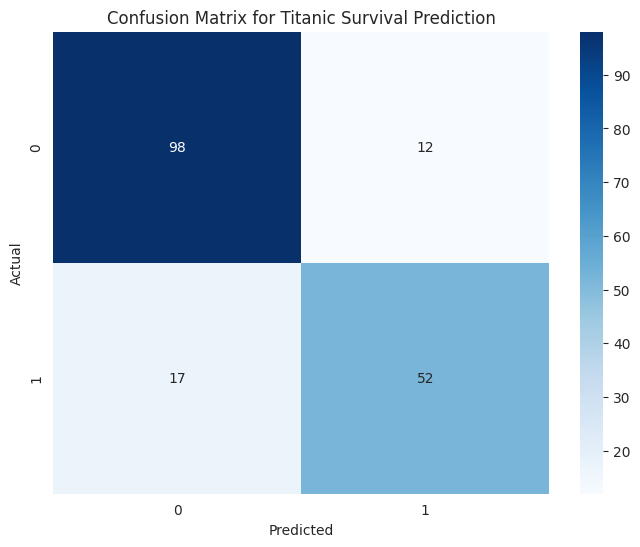

In [9]:
y_pred = clf.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy of the full pipeline: {accuracy:.4f}")

print("Classification Report:")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Titanic Survival Prediction")
plt.show()

### Mini-Challenges / Further Exploration

1.  **Alternative Imputation:** In the `numerical_transformer`, change the `SimpleImputer` strategy from `'median'` to `'mean'` or `'most_frequent'`. How does this affect the final accuracy? When might one strategy be preferred over another?
2.  **Different Scaler:** Replace `StandardScaler` with `MinMaxScaler` in the `numerical_transformer`. Retrain and evaluate the pipeline. Does this change the model's performance? Why might you choose one scaler over the other?
3.  **More Feature Engineering:** Explore creating more features. For example, you could categorize `age` into `AgeGroup` (e.g., child, adult, senior) or `fare` into `FareBand`. How do these new features impact the model's performance? Remember to add them to your `numerical_features` or `categorical_features` lists as appropriate.
4.  **Handling Outliers:** Research methods for detecting and handling outliers (e.g., IQR method, Z-score). Implement a simple outlier removal or capping strategy for a numerical feature like `fare` and observe its effect on the model.
5.  **Different Classifier:** Replace `LogisticRegression` with another classifier like `RandomForestClassifier` or `SVC` within the pipeline. Remember to adjust `max_iter` or other parameters if necessary.

## Additional explanation: what each preprocessing step does

- **Missing values:** The median fills unknown ages with a typical observed age; the mode fills unknown categories with the most common category. These are estimates, not recovered facts. A missing-age indicator can sometimes preserve useful information.
- **Feature engineering:** `FamilySize = sibsp + parch + 1` counts the passenger. `IsAlone` marks a family size of one. This is the same idea already represented by `alone`, so including both can make interpretation of coefficients harder.
- **One-hot encoding:** A category becomes indicator columns so a model can use it without treating labels as ordered numbers. `handle_unknown='ignore'` allows a category seen only at prediction time.
- **Scaling:** `StandardScaler` centers numeric columns and scales by their training-set standard deviation. This helps the logistic regression optimizer and makes coefficients more comparable, although a one-unit change now means one standard deviation.
- **Evaluation:** Accuracy is the fraction classified correctly. The confusion matrix separates actual survivors and non-survivors, so inspect precision and recall as well when the two kinds of error matter differently.

**Important interpretation note:** The original `X` retains `alive`, which directly states whether a passenger survived. Its accuracy therefore cannot be treated as evidence of a useful real-world prediction model. The original notebook also fills missing values before splitting into train and test sets, allowing test-set information to influence imputation. The optional demonstration below starts from the raw dataset and fits imputation inside the training pipeline; it leaves the original exercise intact.

## Optional exploration A: patterns in the original data

Group summaries offer a simple descriptive check before fitting a model. The percentages below describe these Titanic records; they do not show that sex or passenger class caused survival. Some groups may also contain fewer people than others.

In [10]:
# Descriptive summaries; this cell does not change the original model.
for column in ['sex', 'pclass', 'embarked']:
    summary = (df.groupby(column, dropna=False)['survived']
                 .agg(passengers='size', survival_rate='mean')
                 .assign(survival_percent=lambda table: (table['survival_rate'] * 100).round(1))
                 .drop(columns='survival_rate'))
    print(f"\nSurvival by {column}:")
    display(summary)



Survival by sex:


,passengers,survival_percent
sex,,
female,314,74.2
male,577,18.9



Survival by pclass:


,passengers,survival_percent
pclass,,
1,216,63.0
2,184,47.3
3,491,24.2



Survival by embarked:


,passengers,survival_percent
embarked,,
C,168,55.4
Q,77,39.0
S,644,33.7
NaN,2,100.0


## Optional exploration B: a leakage-aware comparison

This example uses only `age`, `fare`, `sibsp`, `parch`, `sex`, `embarked`, and `pclass`. It excludes `alive` because it reveals the answer, and excludes overlapping derived labels such as `who`, `adult_male`, `class`, and `alone` for a simpler baseline. The input comes from raw `df`, so imputers and encoders learn from the training set only. A majority-class classifier provides a reference point. Compare accuracy and survivor recall on the same held-out passengers. The split uses `stratify=y` to keep similar survival proportions in both sets.

In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import recall_score

optional_features = ['age', 'fare', 'sibsp', 'parch', 'sex', 'embarked', 'pclass']
optional_X = df[optional_features].copy()
optional_y = df['survived']
optional_X_train, optional_X_test, optional_y_train, optional_y_test = train_test_split(
    optional_X, optional_y, test_size=0.2, random_state=42, stratify=optional_y
)
optional_numeric = ['age', 'fare', 'sibsp', 'parch']
optional_categorical = ['sex', 'embarked', 'pclass']
optional_preprocessor = ColumnTransformer([
    ('numeric', Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler())
    ]), optional_numeric),
    ('categorical', Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('encode', OneHotEncoder(handle_unknown='ignore'))
    ]), optional_categorical)
])
optional_model = Pipeline([
    ('preprocess', optional_preprocessor),
    ('classify', LogisticRegression(max_iter=1000, random_state=42))
])
optional_baseline = DummyClassifier(strategy='most_frequent')
optional_results = []
for name, estimator in [('Majority-class baseline', optional_baseline),
                        ('Logistic regression', optional_model)]:
    estimator.fit(optional_X_train, optional_y_train)
    predictions = estimator.predict(optional_X_test)
    optional_results.append({
        'Model': name,
        'Accuracy': round(accuracy_score(optional_y_test, predictions), 3),
        'Survivor recall': round(recall_score(optional_y_test, predictions), 3)
    })
display(pd.DataFrame(optional_results))
print('Logistic regression confusion matrix (rows: actual 0/1; columns: predicted 0/1):')
display(pd.DataFrame(confusion_matrix(optional_y_test, optional_model.predict(optional_X_test)),
                     index=['Actual 0', 'Actual 1'], columns=['Predicted 0', 'Predicted 1']))


,Model,Accuracy,Survivor recall
0,Majority-class baseline,0.615,0.000
1,Logistic regression,0.804,0.667


Logistic regression confusion matrix (rows: actual 0/1; columns: predicted 0/1):


,Predicted 0,Predicted 1
Actual 0,98,12
Actual 1,23,46


## Further work with this dataset

1. **Compare missing-age strategies:** Repeat the optional pipeline with median and mean imputation; compare results using the same split. A missingness indicator or group-specific median may help, but fit each method on training data only.
2. **Test family features:** Add `FamilySize` using a transformer inside the pipeline and compare it with the individual `sibsp` and `parch` inputs. Check whether the new feature improves held-out recall, not just training accuracy.
3. **Inspect survival probability:** Use `predict_proba` and test several decision thresholds. A lower threshold may find more survivors but can also increase false positives; choose a threshold based on the intended cost of each error.
4. **Cross-validate on training data:** Use stratified folds to estimate how much performance changes across splits. Keep the test set untouched until model selection is finished.
5. **Compare algorithms:** Try a decision tree or random forest with the same safe input columns. Compare both prediction quality and ease of explanation.
6. **Investigate fairness and scope:** Report performance separately by sex and passenger class and identify small groups. These are historical observations from one voyage; they should not be generalized to other populations.

**How to interpret the optional comparison:** If logistic regression exceeds the majority baseline, the selected features contain predictive information on this split. Its confusion matrix reveals which errors that single accuracy number hides. Neither result repairs the earlier displayed accuracy: that cell still includes `alive`.